# Event support metric

For each event we build a *null model* from the fitted one: same time parameters, same channel
parameters, **except** the channel contribution of the studied event, which is set to 0.
We then compare, at each trial's most likely onset, the event probability under the fitted model with the one
under the null model. A ratio close to 1 means the EEG did not move the probability: the event is placed
by the time distributions only (a potential hallucination).

In [1]:
## Importing these packages is specific for this simulation case
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Importing HMP
import hmp
from hmp import basedata
from hmp.simulations import demo
from hmp.patterns import HalfSine
from hmp.patterndata import PatternData
from hmp.models import EventModel
from hmp.models import EliminativeMethod

cpus = 2 # For multiprocessing, usually a good idea to use multiple CPUs as long as you have enough RAM

# Simulating the data
n_events = 5 #how many events are simulated in the demo
# Performing simulation of trials
epoch_data, sim_source_times, info = demo()
# recovering average simulated times:
avg_simulated = np.mean(np.cumsum(sim_source_times, axis=1), axis=0) * 1000 / epoch_data.sfreq


hmp_data = basedata.default(
    epoch_data,
    duration_id = "response_time", #In which variable of epoch_data are the duration to be modelled
    offsets=0.03, # Adding 30ms before centering event and after duration end to pad for the crosscorrelation, not included in the data afterwards
    n_comp=10 # How many principal components to keep for the fit, the more the better
)
pattern = HalfSine()
# Here we crosscorrelate the data once to avoid doing that at every fit call
pattern_data = PatternData.from_basedata(hmp_data, pattern=pattern)


    Read a total of 4 projection items:
        PCA-v1 (1 x 102) active
        PCA-v2 (1 x 102) active
        PCA-v3 (1 x 102) active
        Average EEG reference (1 x 60) active
Simulating 0_raw.fif
0_raw.fif simulated
Processing dataset demo_dataset
Opening raw data file C:\Epfl\ML\HMP_our_project\hmp-ML\docs\source\notebooks\sample_data\demo_dataset_raw.fif...
    Read a total of 1 projection items:
        Average EEG reference (1 x 60) active
    Range : 0 ... 10378 =      0.000 ...   103.780 secs
Ready.
Reading 0 ... 10378  =      0.000 ...   103.780 secs...
EEG channel type selected for re-referencing
Applying average reference.
Applying a custom ('EEG',) reference.
Removing existing average EEG reference projection.
Filtering raw data in 1 contiguous segment
Setting up low-pass filter at 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal lowpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 pas

C:\Epfl\ML\HMP_project\hmp\hmp\io\utils.py:18: UserWarning: No 'baseline' provided, using default value of (None, 0) seconds 
use 'epoching_kwargs' to override default values
  warn(f"No '{key}' provided, using default value of {value} seconds \n"


Sampling frequency of the instance is already 100.0, returning unmodified.
Adding metadata with 5 columns
50 matching events found
Setting baseline interval to [-0.1, 0.0] s
Applying baseline correction (mode: mean)
Using data from preloaded Raw for 50 events and 211 original time points ...
0 bad epochs dropped
Found 50 trials with positively defined durations and 0 trials without durations (0 or nan)

Rejection summary: 
 0 trials rejected based on threshold of inf 
 0 trials rejected  based on duration limit of (0.01, 1.97) 
 0 with duration but without data (nan at time 0)


## Models to evaluate: eliminative method (all submodels)

In [2]:
model_elim = EliminativeMethod()
lkh_elim, estimates_elim = model_elim.fit_transform(data=pattern_data, cpus=cpus)

n_evnt = [sub.n_events for sub in model_elim.submodels.values()]

Max event that can be fit given minimum duration of 40 is 9
Estimating all solutions for maximal number of events (9)


C:\Epfl\ML\HMP_project\hmp\hmp\estimators\em.py:130: UserWarning: Fit failed, inspect provided starting points
  warn("Fit failed, inspect provided starting points")


Estimating all solutions for 8 events
Estimating all solutions for 7 events
Estimating all solutions for 6 events
Estimating all solutions for 5 events
Estimating all solutions for 4 events
Estimating all solutions for 3 events
Estimating all solutions for 2 events
Estimating all solutions for 1 events


C:\Epfl\ML\HMP_project\hmp\hmp\models\event.py:773: RuntimeWarning: divide by zero encountered in log
  trial_likelihood = np.log(
C:\Epfl\ML\HMP_project\hmp\hmp\models\event.py:777: RuntimeWarning: invalid value encountered in divide
  eventprobs = eventprobs / eventprobs.sum(axis=0)
C:\Epfl\ML\HMP_project\hmp\hmp\models\eliminative.py:182: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'event' ('event',) The recommendation is to set join explicitly for this case.
  xr_eventprobs = xr.concat(event_probs, dim=pd.Index(list(self.submodels), name="n_events"))


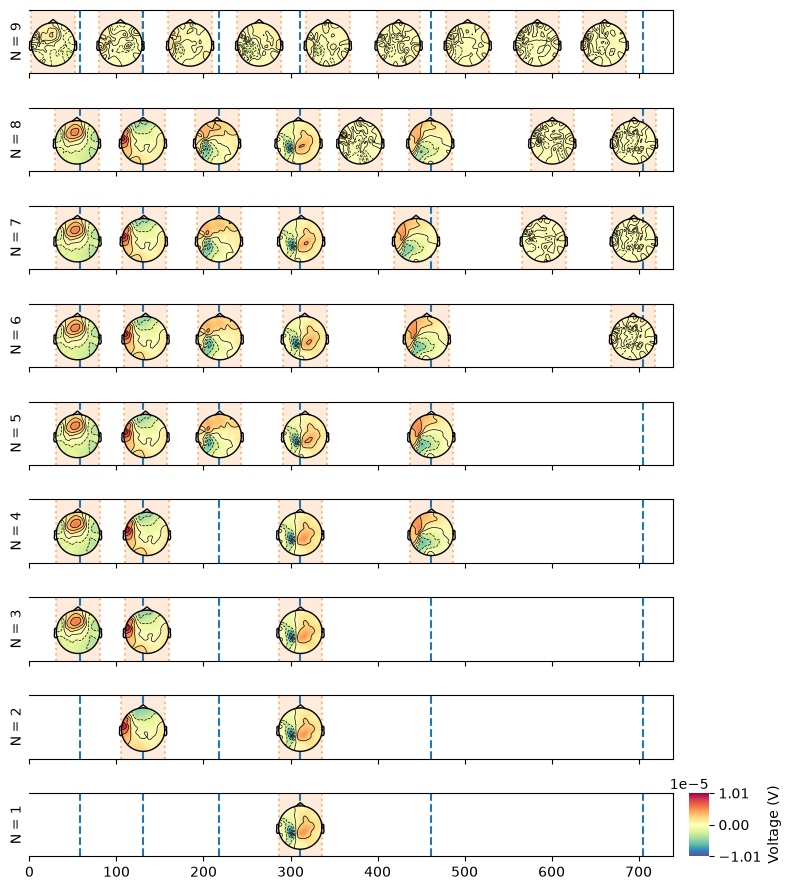

In [3]:
hmp.visu.plot_model(epoch_data, estimates_elim, info, as_time=True, times_to_display=avg_simulated)

## The metric

In [4]:
def _null_pars(model, ev, mode):
    """
    Channel parameters of the null model
    """
    null_ch = np.array(model.channel_pars, copy=True)
    if mode == "single":
        #set the channel contribution of the given event to 0
        null_ch[:, ev, :] = 0
    elif mode == "cumulative":
        #set the channel contribution starting from the given event until the last to 0
        null_ch[:, ev:, :] = 0
    else:
        raise ValueError("mode must be 'single' or 'cumulative'")
    return null_ch

In [5]:
def event_update(model, pdata, mode="single", eps=1e-12, cpus=1):
    """Compare event probabilities from the full model and a model in which some event channel contributions have been removed.
    param:
    model : fitted model
    pdata:  EEG data
    mode:   "single", zero only event e
            "cumulative", zero event e and all later
    eps: small value to avoid division by zero
    cpus: nb of cpus
            
    Returns a DataFrame, one row per (trial, event):
      peak          sample of the most likely onset in the fitted model
      p_full/p_null p(event at peak) under fitted / null model
      update_ratio  p_full / p_null   (~1 => EEG did not move the probability)
      update_rel    the relative change (p_full - p_null) / p_null
      update_diff   absolute difference  p_full - p_null
      lkh_gain      trial log-likelihood of fitted minus null model
    """
    ch, tp = np.asarray(model.channel_pars), np.asarray(model.time_pars)   # (group, event, channel)

    n_events = ch.shape[1]

    #Proba of the full model
    full = model.event_probabilities(pdata, ch, tp, cpus=cpus)
    #Proba of each event at every sample, for every trial
    pf = full.transpose("trial", "sample", "event").values
    #log-likehihood of each trial
    lk_full = np.asarray(full.attrs["trial_lkh"], dtype=float)


    n_trials = pf.shape[0]
    trial_indices = np.arange(n_trials)
    
    result = []
    #loop over all the elements
    for ev in range(n_events):
        
        null_ch = _null_pars(model,ev, mode)

        #Proba of the null model
        null = model.event_probabilities(pdata, null_ch, tp, cpus=cpus)
        #Proba of each event at every sample, for every trial
        pn = null.transpose("trial", "sample", "event").values
        #log-likehihood of each trial
        lk_null = np.asarray(null.attrs["trial_lkh"], dtype=float)

        #select the event with the highest proba for each trial
        event_probs = pf[:,:,ev]
        peak = event_probs.argmax(1)

        #extract proba at the peak
        p_full, p_null = pf[trial_indices, peak, ev], pn[trial_indices, peak, ev]


        proba_diff = p_full - p_null
        proba_ratio = p_full /np.maximum(p_null, eps)
        relative_diff = proba_diff/np.maximum(p_null, eps)
        likelihood_gain = lk_full - lk_null
        
        event_result = pd.DataFrame({
            "n_events": n_events, 
            "event": ev + 1, 
            "trial": trial_indices, 
            "peak": peak,
            "p_full":  p_full,
            "p_null": p_null,
            "update_ratio" : proba_ratio,
            "update_rel" : relative_diff,
            "update_diff" : proba_diff,
            "lkh_gain" : likelihood_gain
        })
        result.append(event_result)
        
    #concatenate every thing into a dataframe, replace infinite value with NaN (when log-likelihood calculation failed)
    return pd.concat(result, ignore_index=True).replace([np.inf, -np.inf], np.nan)


def update_summary(df):
    """
    Summarize probability updates across trials, separetely for each nb of events and event
    """
    
    return df.groupby(["n_events", "event"]).agg(
            ratio_median=("update_ratio", "median"),
            diff_median=("update_diff", "median"),
            share_ratio_gt1=("update_ratio", lambda x: np.nanmean(x > 1)),
            lkh_gain_mean=("lkh_gain", "mean"),
            n_valid=("update_ratio", "count"),
        ).reset_index()

In [6]:
#calculate event for each submodel
upd = pd.concat([event_update(sub, pattern_data) for sub in model_elim.submodels.values()], ignore_index=True)
summary = update_summary(upd)
print(summary.round(2).to_string(index=False))

C:\Epfl\ML\HMP_project\hmp\hmp\models\event.py:773: RuntimeWarning: divide by zero encountered in log
  trial_likelihood = np.log(
C:\Epfl\ML\HMP_project\hmp\hmp\models\event.py:777: RuntimeWarning: invalid value encountered in divide
  eventprobs = eventprobs / eventprobs.sum(axis=0)
C:\Users\angel\AppData\Local\Temp\ipykernel_38584\1929372579.py:58: RuntimeWarning: invalid value encountered in subtract
  likelihood_gain = lk_full - lk_null


 n_events  event  ratio_median  diff_median  share_ratio_gt1  lkh_gain_mean  n_valid
        1      1         42.44         0.91             1.00           8.32       50
        2      1         19.20         0.84             1.00           6.57       50
        2      2         27.18         0.90             1.00           8.58       50
        3      1          8.93         0.74             0.98           6.50       50
        3      2         10.27         0.79             1.00           5.84       50
        3      3         26.84         0.90             1.00           8.60       50
        4      1          8.93         0.74             0.98           6.50       50
        4      2         10.28         0.79             1.00           5.85       50
        4      3         20.62         0.88             1.00           8.81       50
        4      4         19.67         0.82             1.00           5.45       50
        5      1          7.85         0.71             0.96     

## Reading the data
Weakest event per model next to the likelihood curve

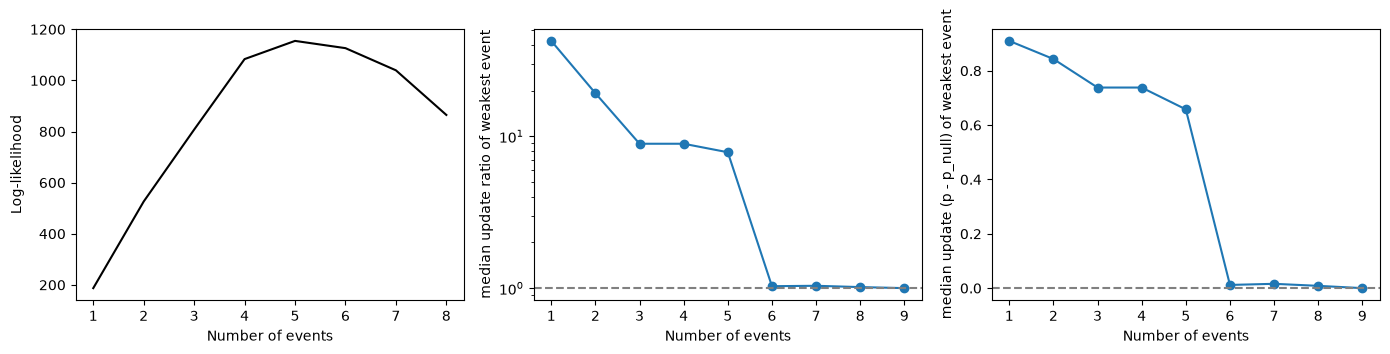

In [7]:
weak = summary.groupby("n_events").agg(weakest_ratio=("ratio_median", "min"),
                                       weakest_diff=("diff_median", "min"))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))

ax[0].plot(n_evnt, lkh_elim, "k") 
ax[0].set_ylabel("Log-likelihood")

ax[1].plot(weak.index, weak.weakest_ratio, "o-")
ax[1].axhline(1, ls="--", c="grey")
ax[1].set_yscale("log")
ax[1].set_ylabel("median update ratio of weakest event")

ax[2].plot(weak.index, weak.weakest_diff, "o-")
ax[2].axhline(0, ls="--", c="grey")
ax[2].set_ylabel("median update (p - p_null) of weakest event")

for a in ax: 
    a.set_xlabel("Number of events")
    
plt.tight_layout()
plt.show()

**Hallucination metric = `update factor` = p(event at its fitted peak) − p(event at that sample when the event is zeroed).**

Near 0 → the EEG did not add anything, the event position comes from the time distributions only.

In [8]:
def plot_update_factor(df, value = "update_diff", ylabel =None):
    """
    dataframe = output of event_update for 1 model (one n_events).
    """
        
    _, ax = plt.subplots(figsize=(7, 3.5))
        
    wide = df.pivot(index="trial", columns="event", values=value)   #(trial, event)
    
    ax.boxplot([wide[e].dropna() for e in wide.columns], positions=wide.columns, widths=0.5)
        
    ax.axhline(0, ls="--", c="grey")
    ax.set_xlabel("Event")
    if ylabel == "log":
        ax.set_ylabel("update factor\nlog(p_full - p_null at peak)")
    else:
        ax.set_ylabel("update factor\n(p_full - p_null at peak)")

    
    return ax


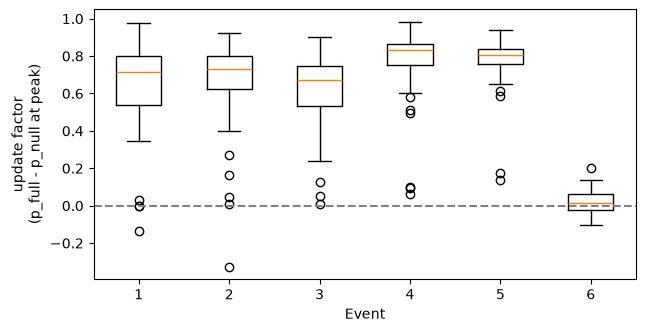

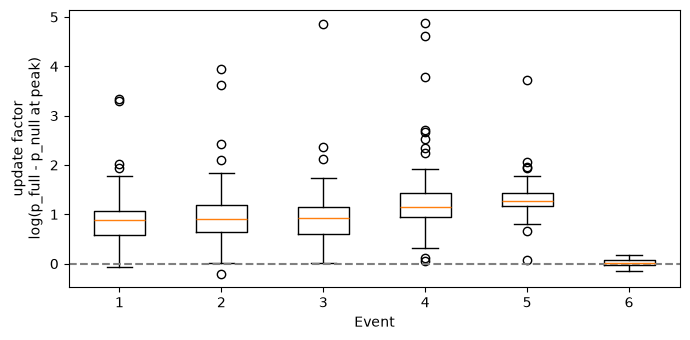

In [9]:
#the model we want to look at
n_show = 6
d = upd[upd.n_events == n_show]


plot_update_factor(d)  #absolute diff

#log ratio
d2 = d.assign(log10_ratio=np.log10(d.update_ratio))

plot_update_factor(d2, value="log10_ratio", ylabel="log") # log diff

for a in ax:
    a.set_title(f"{n_show}-event model")
   
plt.tight_layout()
plt.show()

## More plots

In [10]:
#Helper functions for plotting

def null_event_probs(model, pdata, mode="single", cpus=1):
    """
    Event probabilities of the fitted model and, for each event, of its null model.
    
    Returns full model (trial, sample, event) and null model(trial, sample, event)
    """
    #time parameter
    tp = np.asarray(model.time_pars)
    #Proba of the full model
    full = model.event_probabilities(pdata, np.asarray(model.channel_pars), tp, cpus=cpus)
    #Proba of each event at every sample, for every trial
    full = full.transpose("trial", "sample", "event")


    null = np.zeros(full.shape)
    nb_events = full.shape[2]
    for ev in range(nb_events):
        #Proba of the null model
        n = model.event_probabilities(pdata, _null_pars(model, ev, mode), tp, cpus=cpus)
        #Save the proba only of the event we have just removed
        null[:, :, ev] = n.transpose("trial", "sample", "event").values[:, :, ev]
        
    return full, null


def plot_full_vs_null(model, pdata, trials=None, n_trials=5, mode="single", seed=0, cpus=1):
    """
    Fitted event probabilities (solid) vs null model (dashed), one row per trial.
    Dashed line of event e = probability of e when its own channel contributions are zeroed.

    params:
    model : fitted model
    pdata:  EEG data
    trials: spefic trial to plot
    n_trials : nb of randomly selected trials if trials is NOne
    mode : "single" or "cumulative" for null model
    seed : the given seed
    cpus: nb of cpus
    """
    #calculate proba
    full, null = null_event_probs(model, pdata, mode, cpus)
    
    pf = full.values
    nb_events = pf.shape[2]
    sfreq = full.attrs["sfreq"]

    #select the trial
    if trials is None:
        trials = np.random.default_rng(seed).choice(pf.shape[0], min(n_trials, pf.shape[0]), replace=False)
        
    colors = plt.cm.rainbow(np.linspace(0, 1, nb_events))
    #convert to millisec
    t = np.arange(pf.shape[1]) * 1000 / sfreq

    #one subplot for each trial
    fig, ax = plt.subplots(len(trials), 1, sharex=True, figsize=(9, 1.8 * len(trials)), squeeze=False)
    ax = ax[:, 0]
    #plot each event for each trial
    for a, tr in zip(ax, trials):
        for ev in range(nb_events):
            #full model
            a.plot(t, pf[tr, :, ev], color=colors[ev], label=f"Event {ev + 1}")
            #null model
            a.plot(t, null[tr, :, ev], ls="--", color=colors[ev])
            #mark the peak proba
            pk = pf[tr, :, ev].argmax()
            a.plot(t[pk], pf[tr, pk, ev], "o", color=colors[ev],markersize=4)
            
        a.set_ylabel(f"trial {tr}\nP(event)")
    ax[-1].set_xlabel("Time (ms)")
    ax[0].legend(ncol=nb_events, fontsize=7, loc="upper right")
    ax[0].set_title("solid = full model, dashed = event zeroed (null)")
    fig.tight_layout()
    return fig



### Fitted (solid) vs null (dashed) event probabilities, on a few random trials

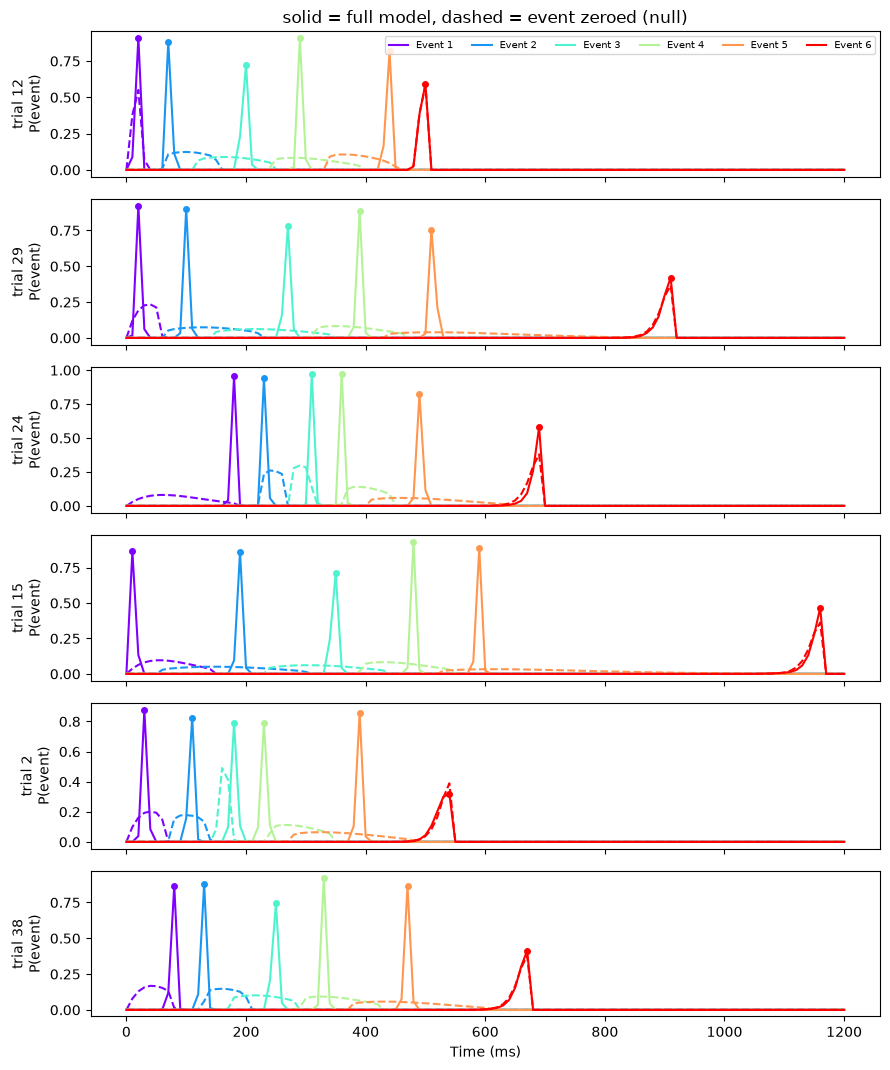

In [11]:
n_show = 6                                   # which eliminative submodel to inspect
model_show = model_elim.submodels[list(model_elim.submodels)[n_evnt.index(n_show)]]
fig = plot_full_vs_null(model_show, pattern_data, n_trials=6, seed=0)
plt.show()

# Now we will test the metrics against real data like in notebook 3

First, we load the required packages and download the data. Depending on your internet connection this can take some time.

In [12]:
import os
import requests

# Declaring path where the EEG data will be stored
epoch_data_path = os.path.join('sample_data', 'eeg')
os.makedirs(epoch_data_path, exist_ok=True)

# URLs of the first 5 participants in the SAT experiment, navigate the osf folder and adapt those if you want to do this tutorial on other data (e.g. P3, N2pc). You can also change 5 to 25 to do the analysis on the full dataset.
base = "https://files.osf.io/v1/resources/29tgr/providers/github/results/replication/SAT_data/"
file_urls = [base + f"processed_500Hz_{(x+1):04d}_epo.fif" for x in range(5)]

# Download and save each file if not already in folder
for i, url in enumerate(file_urls, start=1):
    file_path = os.path.join(epoch_data_path, f'S{i}_epo.fif')
    if not os.path.exists(file_path):
        response = requests.get(url)
        with open(file_path, 'wb') as f:
            f.write(response.content)

# Recovering individual files and participant names
subj_files = [os.path.join(epoch_data_path, f) for f in os.listdir(epoch_data_path) if f.endswith('.fif')]  # Create a list of files with full paths


In the cell below, we read in the MNE epoch files, downsample to 200 Hz and specify the montage that was used for recording.

In [13]:
preprocessing = dict(sfreq=250) #Downsampling from 500Hz to 250Hz for speed and RAM usage
epoch_data, info = hmp.io.read_mne_epochs(subj_files,
                            montage='biosemi64',
                            preprocessing_kwargs=preprocessing,
                            verbose=False)#Turning verbose off for the documentation but it is recommended to leave it on as some output from MNE might be useful

# The duration (i.e. reaction time) data is in milliseconds and we want it in seconds
epoch_data['RT'] /= 1000
# This dataset is in microV, we want the unit in V
epoch_data *= 1e-6

At this point we have the epoched EEG data with 30 channels, which we need to crop between stimulus and response and transform to PC space. To this end, we will perform the default serie of preprocessing steps (see tutorial 1 for details on the unfolding of the steps).

In [16]:
base_data_real = hmp.basedata.default(
    epoch_data, # The data from the io module
    duration_id='RT', # What coordinate in our data contains the duration we want to model
    min_duration = 0.2, # What minimum response time (in second) is reasonable given the task (e.g. anticipation)
    # Minimum duration dictates the number of event that can fit in the data, see FAQ
    max_duration = 2, # same for maximum duration (e.g. distraction or bug), for speed mostly, also to filter clear outliers
    offsets=0.03, # Adding 30ms before centering event and after duration end to pad for the crosscorrelation, not included in the data afterwards
    # Apply a threshold, i.e. reject trial if the absolute value of an electrode exceeds that value
    reject_amplitude = 1e-4, #Here trials get rejected if an electrode exceeds 100microV, useful in the case of artifacts in the data
    n_comp = .99, # How many PCA component we want to compress the data into, here we take as many as necessary to achieve 99% of explained variance, the more the better
    whiten = True, #All components will have unit variance
)

Found 900 trials with positively defined durations and 20 trials without durations (0 or nan)

Rejection summary: 
 0 trials rejected based on threshold of 0.0001 
 1 trials rejected  based on duration limit of (0.2, 2) 
 0 with duration but without data (nan at time 0)
7 components retained, explaining 0.99229% variance


Next, we rearrange the data and calculate the cross correlation with the default halfsine pattern (adjusted to sampling frequency). After this operation the data is arranged as 10 PCs x 899 trials (= 162 633 samples): all epochs of all participants were concatenated and are treated by HMP as one big dataset. For a hierarchical (but computationally much more expensive approach, see [this paper](https://www.biorxiv.org/content/10.64898/2025.12.25.696483v1)).

In [17]:
pattern_real = hmp.patterns.HalfSine(width=50)
pattern_data_real = PatternData.from_basedata(base_data_real, pattern=pattern_real)
print(pattern_data_real.cross_corr.shape)

(162633, 7)


In [18]:
elim_real = EliminativeMethod()
lkh_elim_real, _ = elim_real.fit_transform(data=pattern_data_real, cpus=cpus)

n_evnt_real = [s.n_events for s in elim_real.submodels.values()]

Max event that can be fit given minimum duration of 74 is 6
Estimating all solutions for maximal number of events (6)
Estimating all solutions for 5 events
Estimating all solutions for 4 events
Estimating all solutions for 3 events
Estimating all solutions for 2 events
Estimating all solutions for 1 events


C:\Epfl\ML\HMP_project\hmp\hmp\models\eliminative.py:182: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'event' ('event',) The recommendation is to set join explicitly for this case.
  xr_eventprobs = xr.concat(event_probs, dim=pd.Index(list(self.submodels), name="n_events"))


In [19]:
#calculate the event for each submodel
upd_elim_real = pd.concat([event_update(s, pattern_data_real) for s in elim_real.submodels.values()],
                          ignore_index=True)
summary_elim_real = update_summary(upd_elim_real)
print(summary_elim_real.round(2).to_string(index=False))

 n_events  event  ratio_median  diff_median  share_ratio_gt1  lkh_gain_mean  n_valid
        1      1          1.33         0.03             0.85           0.79      899
        2      1          7.59         0.06             1.00           0.52      899
        2      2          1.30         0.03             0.84           0.79      899
        3      1          2.87         0.05             0.99           0.42      899
        3      2          6.14         0.06             1.00           0.68      899
        3      3          1.29         0.03             0.82           0.79      899
        4      1          2.90         0.05             0.99           0.42      899
        4      2          5.04         0.06             1.00           0.67      899
        4      3          2.88         0.03             0.99           0.38      899
        4      4          1.05         0.01             0.61           0.75      899
        5      1          1.13         0.02             0.69     

Weakest event per model next to the likelihood curve

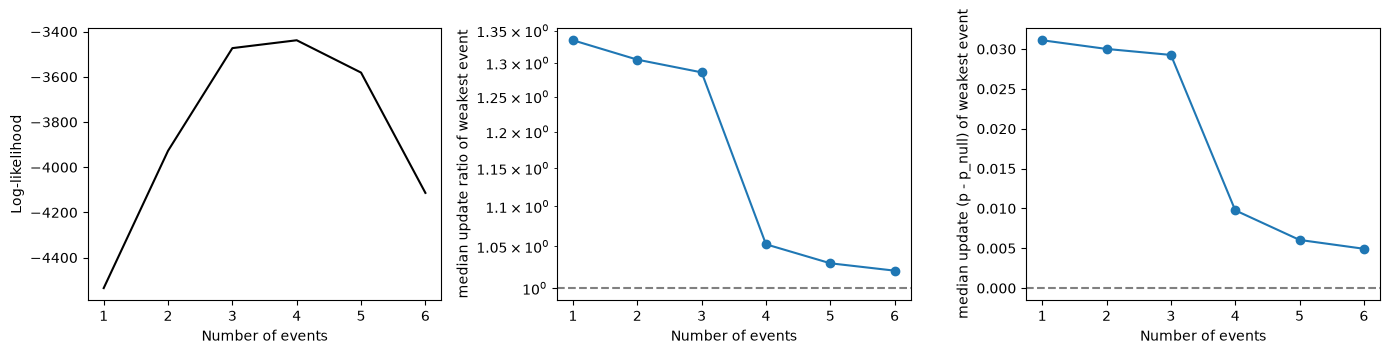

In [21]:
weak = summary_elim_real.groupby("n_events").agg(weakest_ratio=("ratio_median", "min"),
                                       weakest_diff=("diff_median", "min"))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))

ax[0].plot(n_evnt_real, lkh_elim_real, "k") 
ax[0].set_ylabel("Log-likelihood")

ax[1].plot(weak.index, weak.weakest_ratio, "o-")
ax[1].axhline(1, ls="--", c="grey")
ax[1].set_yscale("log")
ax[1].set_ylabel("median update ratio of weakest event")

ax[2].plot(weak.index, weak.weakest_diff, "o-")
ax[2].axhline(0, ls="--", c="grey")
ax[2].set_ylabel("median update (p - p_null) of weakest event")

for a in ax: 
    a.set_xlabel("Number of events")
    
plt.tight_layout()
plt.show()

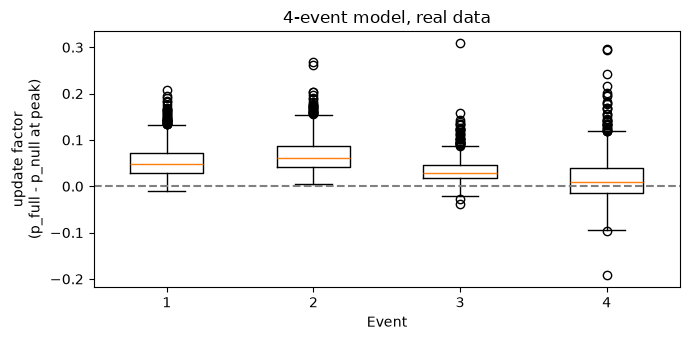

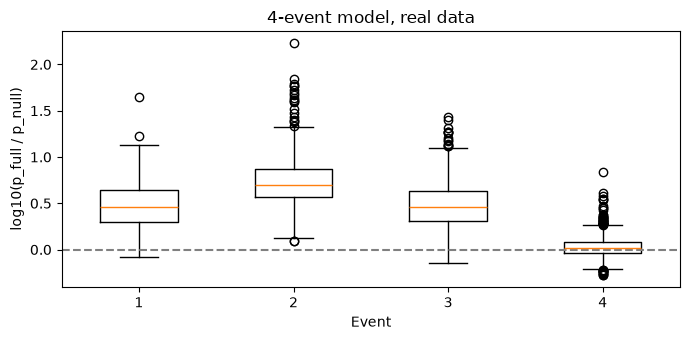

In [34]:
n_show_real = 4
d_real = upd_elim_real[upd_elim_real.n_events == n_show_real]

# absolute diff
ax_diff = plot_update_factor(d_real)
ax_diff.set_title(f"{n_show_real}-event model, real data")
ax_diff.figure.tight_layout()

# log diff
d2_real = d_real.assign(log10_ratio=np.log10(d_real.update_ratio).replace([-np.inf, np.inf], np.nan))
ax_log = plot_update_factor(d2_real, value="log10_ratio", ylabel="log")
ax_log.set_ylabel("log10(p_full / p_null)")      # the "log" label of the function says log(p_full - p_null)
ax_log.set_title(f"{n_show_real}-event model, real data")
ax_log.figure.tight_layout()
plt.show()


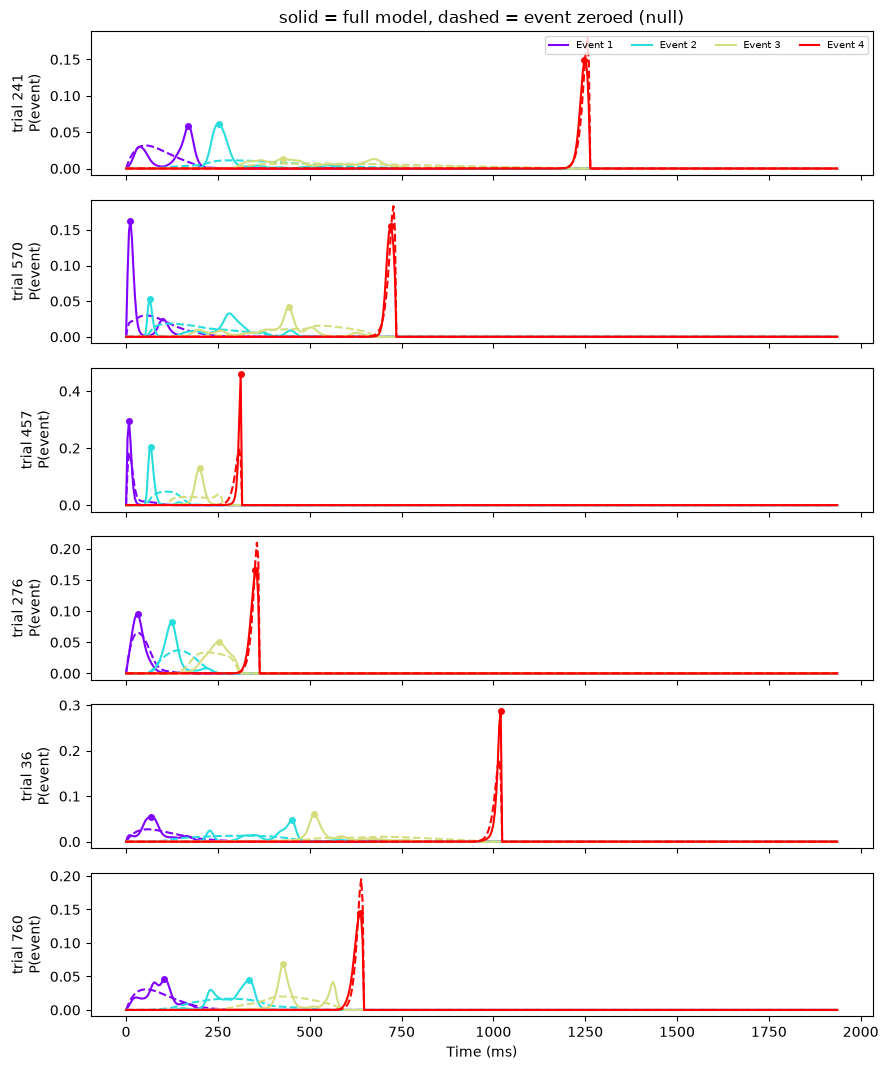

In [35]:
n_show = 4
model_show = elim_real.submodels[list(elim_real.submodels)[n_evnt_real.index(n_show)]]
fig = plot_full_vs_null(model_show, pattern_data_real, n_trials=6, seed=0)
plt.show()

In [75]:
def flag_hallucinations(df, update_factor_frac=0.25, lh_frac=0.55, min_update_factor=0.02, min_lh=0.02):
    """
    Flag events if they have both a low update factor(median p_full - p_null at the peak) and a low likelihood relative to other events on the same model

    Input:
    df: the given dataFrame
    update_factor_frac: the relative threshold compare to other value for update factor
    lh_frac: the relative threshold for the likelihood gain
    min_update_factor: the minimum threshold for update factor
    min_lh: the minimum threshold for likelihood gain

    Output:
        the updated dataframe with new columns:
            - "low_update_factor": Boolean to tell if the update factor is low
            - "low_lh_gain": Boolean to tell if the likelihood is low
            - "hallucinated": Boolean to tell if the event was hallucinated
    """
    out = df.copy()

    #diff median is equivalent to update factor
    #median over the other events of the same model
    for col in ("diff_median", "lkh_gain_mean"):
        ref = col + "_ref"
        out[ref] = np.nan
        #events are compared with other events belonging to the same model
        for _, g in out.groupby("n_events"):
            #current event is excluded
            for i in g.index:
                out.loc[i, ref] = g[col].drop(i).median()

    out["low_update_factor"] = out.diff_median < np.fmax(update_factor_frac * out.diff_median_ref, min_update_factor)
    out["low_lh_gain"] = out.lkh_gain_mean < np.fmax(lh_frac * out.lkh_gain_mean_ref, min_lh)
    out["hallucinated"] = out.low_update_factor & out.low_lh_gain
    return out


cols = ["n_events", "event", "diff_median", "lkh_gain_mean", "low_update_factor", "low_lh_gain", "hallucinated"]

for name, s in [("simulation", summary), ("real data", summary_elim_real)]:
    print(f"\n{name}")
    print(flag_hallucinations(s)[cols].round(3).to_string(index=False))


simulation
 n_events  event  diff_median  lkh_gain_mean  low_update_factor  low_lh_gain  hallucinated
        1      1        0.910          8.323              False        False         False
        2      1        0.843          6.569              False        False         False
        2      2        0.901          8.582              False        False         False
        3      1        0.738          6.505              False        False         False
        3      2        0.792          5.844              False        False         False
        3      3        0.901          8.604              False        False         False
        4      1        0.738          6.504              False        False         False
        4      2        0.791          5.847              False        False         False
        4      3        0.882          8.806              False        False         False
        4      4        0.821          5.450              False        False  